In [1]:
# 1. Импорт библиотек

using Pkg
## Pkg.add("Plots") 
using Plots # подключаем функции plot(), plot!(), xlabel! и т.д.
using Printf # знаки после запятой

In [2]:
# 2. Ввод исходных данных

print("Введите ёмкость соты C (целое число): ")
C = parse(Int, readline())

print("Введите полнодоступную часть пропускной способности соты g: ")
g = parse(Int, readline())

print("Введите интенсивность λ1: ")
lambda1 = parse(Float64, readline())

print("Введите интенсивность λ2: ")
lambda2 = parse(Float64, readline())

print("Введите интенсивность обслуживания μ1: ")
mu1 = parse(Float64, readline())

print("Введите интенсивность обслуживания μ2: ")
mu2 = parse(Float64, readline())

## 2.1 Интенсивность предложенной нагрузки: ρ = λ / μ
rho1 = lambda1 / mu1
rho2 = lambda2 / mu2

println()
println("Введены данные: C=$C, g=$g, λ1=$lambda1, λ2=$lambda2, μ1=$mu1, μ2=$mu2")

println()
println("Посчитанные данные: ρ1=$rho1, ρ2=$rho2")

Введите ёмкость соты C (целое число): 

stdin>  4


Введите полнодоступную часть пропускной способности соты g: 

stdin>  3


Введите интенсивность λ1: 

stdin>  1


... (3 outputs left out)

stdin>  2


Введите интенсивность обслуживания μ2: 

stdin>  1



Введены данные: C=4, g=3, λ1=1.0, λ2=1.0, μ1=2.0, μ2=1.0

Посчитанные данные: ρ1=0.5, ρ2=1.0


In [3]:
# 3. Функции расчёта характеристик модели

## 3.1 Пространство состояний системы X
function state_space(C::Int, g::Int)
    # пустой список пар (n1, n2)
    states = Tuple{Int, Int}[]            
    
    for n1 in 0:g # заявок 1-го типа не больше g
        for n2 in 0:(C - n1) # суммарно заявок не больше C
            push!(states, (n1, n2))
        end
    end

    return states
end

state_space (generic function with 1 method)

In [4]:
## 3.2 Стационарное распределение вероятностей состояний системы p(n1, n2)
function stationary_probability(rho1::Float64, rho2::Float64, n1::Int, n2::Int, C::Int, g::Int)
    # считаем нормировочную константу (part_sum)
    part_sum = 0.0
    
    for i in 0:g
        for j in 0:(C - i)
            part_sum += (rho1^i / factorial(big(i))) * (rho2^j / factorial(big(j)))
        end
    end

    p00 = 1.0 / part_sum

    # вероятность конкретного состояния
    unnorm = (rho1^n1 / factorial(big(n1))) * (rho2^n2 / factorial(big(n2)))
    p = unnorm * p00

    return p
end

stationary_probability (generic function with 1 method)

In [5]:
## 3.3 Множество блокировок запросов услуги i-ого типа
function blocking_set(X::Vector{Tuple{Int,Int}}, C::Int, g::Int, service_type::Int)
    # пустой список пар (n1, n2)
    Bi = Tuple{Int, Int}[]
    
    for (n1, n2) in X
        if service_type == 1 && (n1 == g || (n1 + n2 == C)) # для i = 1: блокировка, если n1 = g или n1 + n2 = C 
            push!(Bi, (n1, n2))
        elseif service_type == 2 && n1 + n2 == C # для i = 2: блокировка, если n1 + n2 = C
            push!(Bi, (n1, n2))
        end
    end
    
    return Bi
end

blocking_set (generic function with 1 method)

In [6]:
## 3.4 Множество приёма заявок услуги i-ого типа
function admission_set(X::Vector{Tuple{Int,Int}}, Bi::Vector{Tuple{Int,Int}})
    
    # пустой список пар (n1, n2)
    Si = Tuple{Int, Int}[]
    
    for s in X
        if !(s in Bi) # если s НЕ принадлежит множеству блокировок 
            push!(Si, s)
        end
    end
    
    return Si
end

admission_set (generic function with 1 method)

In [7]:
## 3.5 Вероятность блокировки запроса на предоставление услуги i-ого типа 
function blocking_probability(Bi::Vector{Tuple{Int,Int}}, probs::Dict{Tuple{Int,Int}, Float64})
    # накопленная вероятность блокировки
    Bi_prob = 0.0
    
    for s in Bi
        Bi_prob += probs[s] # достаём готовую вероятность p(s) и суммируем
    end
    
    return Bi_prob
end

blocking_probability (generic function with 1 method)

In [8]:
## 3.6 Среднее число обслуживаемых в системе запросов i-ого типа
function average_requests(probs::Dict{Tuple{Int,Int}, Float64}, C::Int, g::Int, service_type::Int)
    # накопленное среднее число заявок i-го типа
    N_i = 0.0  
    
    for n1 in 0:g
        for n2 in 0:(C - n1)
            p = probs[(n1, n2)] # готовая вероятность состояния
            if service_type == 1
                N_i += n1 * p # n1 * p(n1, n2)
            elseif service_type == 2
                N_i += n2 * p # вклад n2 * p(n1, n2)
            end
        end
    end
    
    return N_i                                
end

average_requests (generic function with 1 method)

In [9]:
# 4.Определение пространства состояний системы X
X = state_space(C, g)

println("Число состояний |X| = ", length(X))
println("=== Пространство состояний X ===")
for (n1, n2) in X
    println("(", n1, ", ", n2, ")")
end

Число состояний |X| = 14
=== Пространство состояний X ===
(0, 0)
(0, 1)
(0, 2)
(0, 3)
(0, 4)
(1, 0)
(1, 1)
(1, 2)
(1, 3)
(2, 0)
(2, 1)
(2, 2)
(3, 0)
(3, 1)


In [10]:
# 5. Определение множества блокировок B1 и B2
B1_set = blocking_set(X, C, g, 1)

println("|B1| = ", length(B1_set))
println("=== Множество блокировок 1-ого типа B1 ===")
for b in B1_set
    println(b)
end

println()

B2_set = blocking_set(X, C, g, 2)

println("|B2| = ", length(B2_set))
println("=== Множество блокировок 2-ого типа B2 ===")
for b in B2_set
    println(b)
end

|B1| = 5
=== Множество блокировок 1-ого типа B1 ===
(0, 4)
(1, 3)
(2, 2)
(3, 0)
(3, 1)

|B2| = 4
=== Множество блокировок 2-ого типа B2 ===
(0, 4)
(1, 3)
(2, 2)
(3, 1)


In [11]:
# 6. Определение множества приёма заявок S1 и S2
S1_set = admission_set(X, B1_set)

println("|S1| = ", length(S1_set))
println("=== Множество приёма заявок 1-ого типа S1 ===")
for s in S1_set
    println(s)
end

println()

S2_set = admission_set(X, B2_set)

println("|S2| = ", length(S2_set))
println("=== Множество приёма заявок 2-ого типа S2 ===")
for s in S2_set
    println(s)
end

|S1| = 9
=== Множество приёма заявок 1-ого типа S1 ===
(0, 0)
(0, 1)
(0, 2)
(0, 3)
(1, 0)
(1, 1)
(1, 2)
(2, 0)
(2, 1)

|S2| = 10
=== Множество приёма заявок 2-ого типа S2 ===
(0, 0)
(0, 1)
(0, 2)
(0, 3)
(1, 0)
(1, 1)
(1, 2)
(2, 0)
(2, 1)
(3, 0)


In [12]:
# 7. Расчёт и вывод стационарного распределения p(n1, n2)

total = 0.0
probs = Dict{Tuple{Int,Int}, Float64}()

println("=== Стационарное распределение вероятностей p(n1, n2) ===")
for n1 in 0:g
    for n2 in 0:(C - n1)
        p = stationary_probability(rho1, rho2, n1, n2, C, g)
        @printf("p(%d,%d) = %.10f\n", n1, n2, p)
        total += p
        probs[(n1, n2)] = p # запоминаем вероятность состояния
    end
end

## 7.1 Проверка условия нормировки
println()
@printf("Сумма всех вероятностей: %.10f\n", total)

=== Стационарное распределение вероятностей p(n1, n2) ===
p(0,0) = 0.2274881517
p(0,1) = 0.2274881517
p(0,2) = 0.1137440758
p(0,3) = 0.0379146919
p(0,4) = 0.0094786730
p(1,0) = 0.1137440758
p(1,1) = 0.1137440758
p(1,2) = 0.0568720379
p(1,3) = 0.0189573460
p(2,0) = 0.0284360190
p(2,1) = 0.0284360190
p(2,2) = 0.0142180095
p(3,0) = 0.0047393365
p(3,1) = 0.0047393365

Сумма всех вероятностей: 1.0000000000


In [13]:
# 8. Вероятностные характеристики для введённых данных

## 8.1 Вероятность блокировки запроса B1
B1 = blocking_probability(B1_set, probs)

@printf("Вероятность блокировки запроса B1 = %.10f\n", B1)

Вероятность блокировки запроса B1 = 0.0521327014


In [14]:
## 8.2 Вероятность блокировки запроса B1
B2 = blocking_probability(B2_set, probs)

@printf("Вероятность блокировки запроса B2 = %.10f\n", B2)

Вероятность блокировки запроса B2 = 0.0473933649


In [15]:
## 8.3 Среднее число обслуживаемых запросов N1
N1 = average_requests(probs, C, g, 1)

@printf("Среднее число обслуживаемых запросов N1 = %.10f\n", N1)

Среднее число обслуживаемых запросов N1 = 0.4739336493


In [16]:
## 8.4 Среднее число обслуживаемых запросов N2
N2 = average_requests(probs, C, g, 2)

@printf("Среднее число обслуживаемых запросов N2 = %.10f\n", N2)

Среднее число обслуживаемых запросов N2 = 0.9526066351


In [17]:
## 8.5 Среднее число обслуживаемых запросов N
N = N1 + N2

@printf("Среднее число обслуживаемых запросов N = %.10f\n", N)

Среднее число обслуживаемых запросов N = 1.4265402844


In [18]:
# 9. Диаграмма интенсивностей переходов
function draw_state_diagram(X, B1_set, B2_set, C::Int, g::Int, lambda1::Float64, lambda2::Float64, mu1::Float64, mu2::Float64)
    Xset = Set(X) # множество для быстрой проверки "состояние принадлежит X"

    # подпись интенсивности гибели: коэффициент 1 не пишем (просто μ, а не 1μ)
    death_label(k, mu_sym) = k == 1 ? mu_sym : string(k, mu_sym)

    plt = plot(size = (750, 850),
               xlims = (-0.6, g + 0.6),
               ylims = (-0.6, C + 0.6),
               xticks = 0:g,
               yticks = 0:C,
               xlabel = "n₁ (число запросов 1-го типа)",
               ylabel = "n₂ (число запросов 2-го типа)",
               title = "Диаграмма интенсивностей переходов",
               grid = false,
               legend = :outertopright)

    # стрелки переходов
    for (n1, n2) in X
        # горизонтальные переходы: (n1, n2) <-> (n1+1, n2)
        if (n1 + 1, n2) in Xset
            # вправо: λ1
            plot!(plt, [n1 + 0.2, n1 + 0.8], [n2 + 0.07, n2 + 0.07],
                  arrow = :closed, color = :royalblue, linewidth = 1.5, label = "")
            annotate!(plt, n1 + 0.5, n2 + 0.19, text("λ₁", 9, :royalblue))
            # влево: (n1+1)·μ1
            plot!(plt, [n1 + 0.8, n1 + 0.2], [n2 - 0.07, n2 - 0.07],
                  arrow = :closed, color = :gray, linewidth = 1.5, label = "")
            annotate!(plt, n1 + 0.5, n2 - 0.19, text(death_label(n1 + 1, "μ₁"), 9, :gray))
        end

        # вертикальные переходы: (n1, n2) <-> (n1, n2+1)
        if (n1, n2 + 1) in Xset
            # вверх: λ2
            plot!(plt, [n1 - 0.07, n1 - 0.07], [n2 + 0.2, n2 + 0.8],
                  arrow = :closed, color = :crimson, linewidth = 1.5, label = "")
            annotate!(plt, n1 - 0.26, n2 + 0.5, text("λ₂", 9, :crimson))
            # вниз: (n2+1)·μ2
            plot!(plt, [n1 + 0.07, n1 + 0.07], [n2 + 0.8, n2 + 0.2],
                  arrow = :closed, color = :seagreen, linewidth = 1.5, label = "")
            annotate!(plt, n1 + 0.28, n2 + 0.5, text(death_label(n2 + 1, "μ₂"), 9, :seagreen))
        end
    end

    # состояния (кружки), раскрашенные по типу
    both  = [s for s in X if (s in B1_set) && (s in B2_set)] # блокируются оба типа
    only1 = [s for s in X if (s in B1_set) && !(s in B2_set)] # блокируется только 1-й тип
    free  = [s for s in X if !(s in B1_set) && !(s in B2_set)] # принимаются оба типа

    scatter!(plt, first.(free), last.(free), markersize = 24, color = :lightblue,
             markerstrokecolor = :black, label = "принимаются запросы обоих типов")
    scatter!(plt, first.(only1), last.(only1), markersize = 24, color = :orange,
             markerstrokecolor = :black, label = "блокируется только услуга 1 (B1)")
    scatter!(plt, first.(both), last.(both), markersize = 24, color = :tomato,
             markerstrokecolor = :black, label = "блокируются обе услуги (B1 и B2)")

    # подписи внутри кружков
    for (n1, n2) in X
        annotate!(plt, n1, n2, text("$n1,$n2", 8, :black))
    end

    return plt
end

draw_state_diagram (generic function with 1 method)

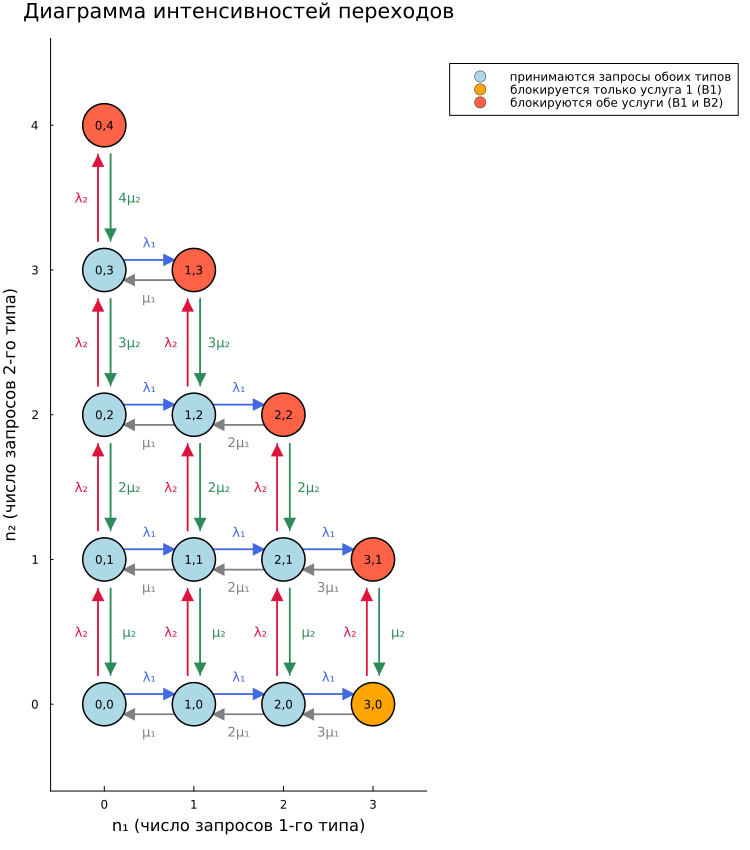

In [19]:
# 10. Построние диаграммы интенсивностей переходов
diagram = draw_state_diagram(X, B1_set, B2_set, C, g, lambda1, lambda2, mu1, mu2)
diagram

In [20]:
# 11. Расчёт данных для графиков

# Случай 1: λ2 фиксирована, меняется λ1

lambda1_range = 0:0.2:16 # последовательность значений λ1 с шагом 0.5

B1_range_lam1 = Float64[] # 4 пустых массива (результат для каждой точки диапазона)
B2_range_lam1 = Float64[]
N1_range_lam1 = Float64[]
N2_range_lam1 = Float64[]

for lam1 in lambda1_range # цикл - перебирает каждое значение λ1 из диапазона 

    rho1_i = lam1 / mu1 # нагрузка 1-го типа под текущее λ1

    # заново считаем распределение для этого λ1 и запоминаем в словаре
    probs_i_lam1 = Dict{Tuple{Int,Int}, Float64}()
    for (n1, n2) in X
        probs_i_lam1[(n1, n2)] = stationary_probability(rho1_i, rho2, n1, n2, C, g)
    end
    
    # множества блокировок B1_set, B2_set от λ1 не зависят, берём готовые
    push!(B1_range_lam1, blocking_probability(B1_set, probs_i_lam1))
    push!(B2_range_lam1, blocking_probability(B2_set, probs_i_lam1))
    push!(N1_range_lam1, average_requests(probs_i_lam1, C, g, 1))
    push!(N2_range_lam1, average_requests(probs_i_lam1, C, g, 2))
end

N_range_lam1 = N1_range_lam1 .+ N2_range_lam1 # поэлементная сумма массивов

# Случай 2: λ1 фиксирована, меняется λ2

lambda2_range = 0:0.2:16 # последовательность значений λ2 с шагом 0.5

B1_range_lam2 = Float64[] # 4 пустых массива (результат для каждой точки диапазона)
B2_range_lam2 = Float64[]
N1_range_lam2 = Float64[]
N2_range_lam2 = Float64[]

for lam2 in lambda2_range # цикл - перебирает каждое значение λ2 из диапазона 

    rho2_i = lam2 / mu2 # нагрузка 2-го типа под текущее λ2

    # заново считаем распределение для этого λ2 и запоминаем в словаре
    probs_i_lam2 = Dict{Tuple{Int,Int}, Float64}()
    for (n1, n2) in X
        probs_i_lam2[(n1, n2)] = stationary_probability(rho1, rho2_i, n1, n2, C, g)
    end
    
    # множества блокировок B1_set, B2_set от λ2 не зависят, берём готовые
    push!(B1_range_lam2, blocking_probability(B1_set, probs_i_lam2))
    push!(B2_range_lam2, blocking_probability(B2_set, probs_i_lam2))
    push!(N1_range_lam2, average_requests(probs_i_lam2, C, g, 1))
    push!(N2_range_lam2, average_requests(probs_i_lam2, C, g, 2))
end

N_range_lam2 = N1_range_lam2 .+ N2_range_lam2; # поэлементная сумма массивов

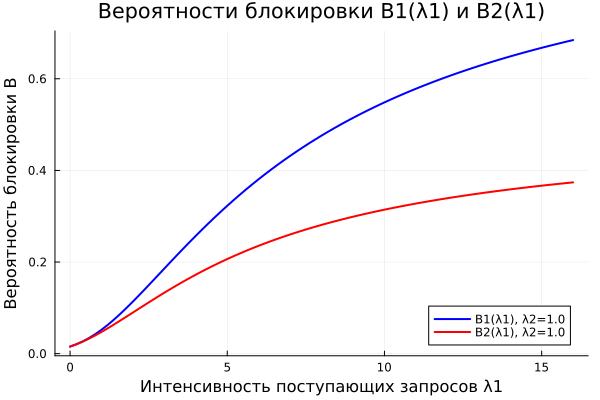

In [21]:
# 12. Построение графиков

#№ 12.1 Графики зависимости вероятности блокировки B1 и B2 от интенсивности λ1 при фиксированном λ2
plot(lambda1_range, B1_range_lam1,
    label = "B1(λ1), λ2=$lambda2",
    xlabel = "Интенсивность поступающих запросов λ1",
    ylabel = "Вероятность блокировки B",
    title = "Вероятности блокировки B1(λ1) и B2(λ1)",
    linewidth = 2,
    color = :blue,
    legend = :bottomright)
plot!(lambda1_range, B2_range_lam1,
    label = "B2(λ1), λ2=$lambda2",
    linewidth = 2,
    color = :red)

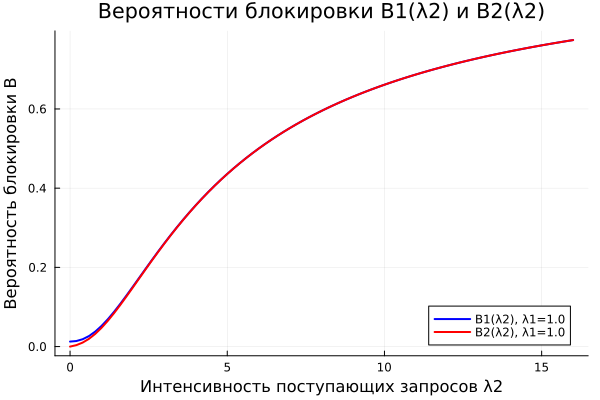

In [22]:
#№ 12.2 Графики зависимости вероятности блокировки B1 и B2 от интенсивности λ2 при фиксированном λ`
plot(lambda2_range, B1_range_lam2,
    label = "B1(λ2), λ1=$lambda1",
    xlabel = "Интенсивность поступающих запросов λ2",
    ylabel = "Вероятность блокировки B",
    title = "Вероятности блокировки B1(λ2) и B2(λ2)",
    linewidth = 2,
    color = :blue,
    legend = :bottomright)
plot!(lambda2_range, B2_range_lam2,
    label = "B2(λ2), λ1=$lambda1",
    linewidth = 2,
    color = :red)

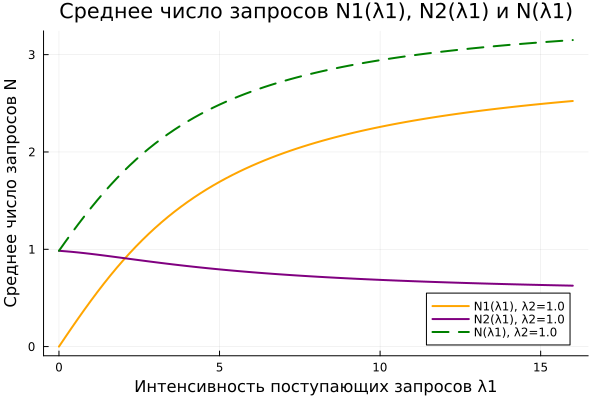

In [23]:
#№ 12.3 Графики зависимости среднего числа N1, N2 и N от интенсивности λ1 при фиксированном λ2
plot(lambda1_range, N1_range_lam1,
    label = "N1(λ1), λ2=$lambda2",
    xlabel = "Интенсивность поступающих запросов λ1",
    ylabel = "Среднее число запросов N",
    title = "Среднее число запросов N1(λ1), N2(λ1) и N(λ1)",
    linewidth = 2,
    color = :orange,
    legend = :bottomright)
plot!(lambda1_range, N2_range_lam1,
    label = "N2(λ1), λ2=$lambda2",
    linewidth = 2,
    color = :purple)
plot!(lambda1_range, N_range_lam1,
    label = "N(λ1), λ2=$lambda2",
    linewidth = 2,
    linestyle = :dash,
    color = :green)

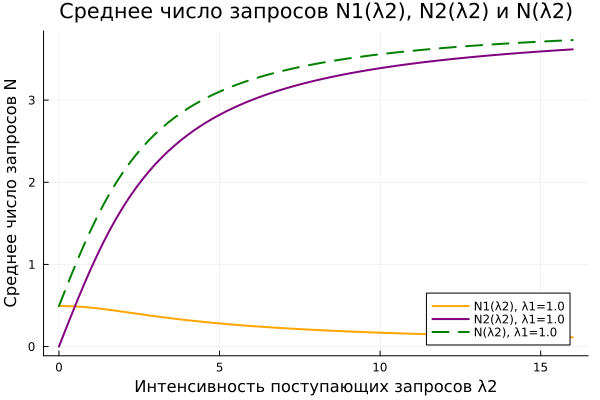

In [24]:
#№ 12.4 Графики зависимости среднего числа N1, N2 и N от интенсивности λ2 при фиксированном λ1
plot(lambda2_range, N1_range_lam2,
    label = "N1(λ2), λ1=$lambda1",
    xlabel = "Интенсивность поступающих запросов λ2",
    ylabel = "Среднее число запросов N",
    title = "Среднее число запросов N1(λ2), N2(λ2) и N(λ2)",
    linewidth = 2,
    color = :orange,
    legend = :bottomright)
plot!(lambda2_range, N2_range_lam2,
    label = "N2(λ2), λ1=$lambda1",
    linewidth = 2,
    color = :purple)
plot!(lambda2_range, N_range_lam2,
    label = "N(λ2), λ1=$lambda1",
    linewidth = 2,
    linestyle = :dash,
    color = :green)